In [26]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import random 

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

In [27]:
path = r"C:\Users\PRASANNA\OneDrive\Attachments\Desktop\DL datasets\cifar10"

train_data = pd.read_csv(path + r"\train.csv")
test_data = pd.read_csv(path + r"\test.csv")

In [28]:
train_data.shape

(50000, 3073)

In [29]:
test_data.shape

(10000, 3072)

In [30]:
x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values
x_test = test_data.values

In [31]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)

(50000, 3072)
(50000,)
(10000, 3072)


In [32]:
class_names = [
"Airplane",
"Automobile",
"Bird",
"Cat",
"Deer",
"Dog",
"Frog",
 "Horse",
 "ship",
 "truck"
]

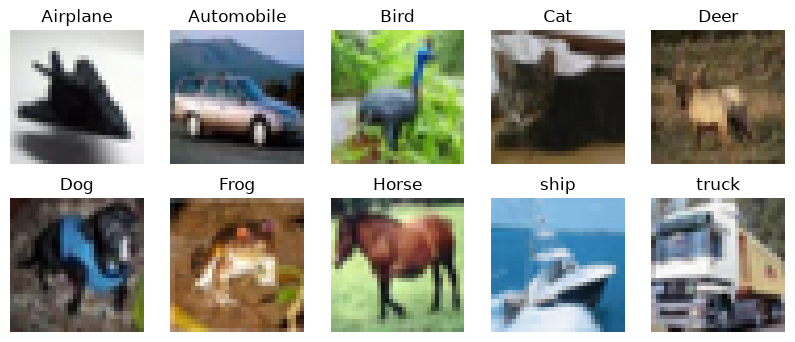

In [33]:
plt.figure(figsize=(10, 4))

for i in range(10):
    n = np.where(y_train == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[n].reshape(3, 32, 32).transpose(1,2,0))
    plt.title(class_names[i])
    plt.axis('off')
plt.show()
   

In [34]:
x_train = x_train.reshape(-1, 32, 32, 3)
x_test = x_test.reshape(-1, 32, 32, 3)

In [35]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0


In [36]:
x_train,x_val,y_train,y_val = train_test_split (
 x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

In [37]:
print("Training Data:", x_train.shape)
print("Training Labels:", y_train.shape)
print("Validation Data:", x_val.shape)
print("Validation Labels:", y_val.shape)

Training Data: (45000, 32, 32, 3)
Training Labels: (45000,)
Validation Data: (5000, 32, 32, 3)
Validation Labels: (5000,)


In [38]:
model = Sequential([
    Flatten(input_shape=(3,32,32)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\PRASANNA\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [39]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [40]:
h = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.3192 - loss: 1.8930 - val_accuracy: 0.3812 - val_loss: 1.7435
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.3932 - loss: 1.7019 - val_accuracy: 0.4006 - val_loss: 1.6679
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4191 - loss: 1.6293 - val_accuracy: 0.4072 - val_loss: 1.6509
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4414 - loss: 1.5630 - val_accuracy: 0.4338 - val_loss: 1.5884
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4566 - loss: 1.5222 - val_accuracy: 0.4424 - val_loss: 1.5677
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4667 - loss: 1.4912 - val_accuracy: 0.4386 - val_loss: 1.5797
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4759 - loss: 1.4682 - val_accuracy: 0.4492 - val_loss: 1.5362
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4847 - loss: 1.4415 - val_acc

In [41]:
val_loss,val_acc = model.evaluate(x_val,y_val)
print("val_loss:",val_loss)
print("val_acc:",val_acc * 100,"%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4768 - loss: 1.4781
val_loss: 1.4780726432800293
val_acc: 47.679999470710754 %


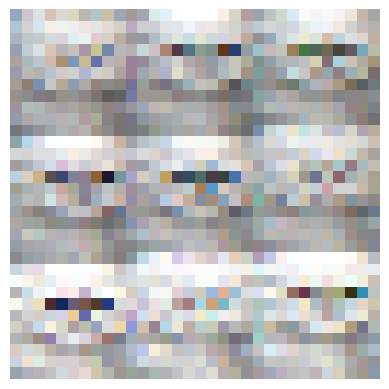

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
actual: truck
predicted: truck


In [54]:
n=random.randint(0,len(x_val)-1)


plt.imshow(x_test[n])
plt.axis("off")
plt.show()

pred=model.predict(x_val[n].reshape(1,32,32,3))

print("actual:",class_names[y_val[n]
    ])
print("predicted:",class_names[np.argmax(pred)])

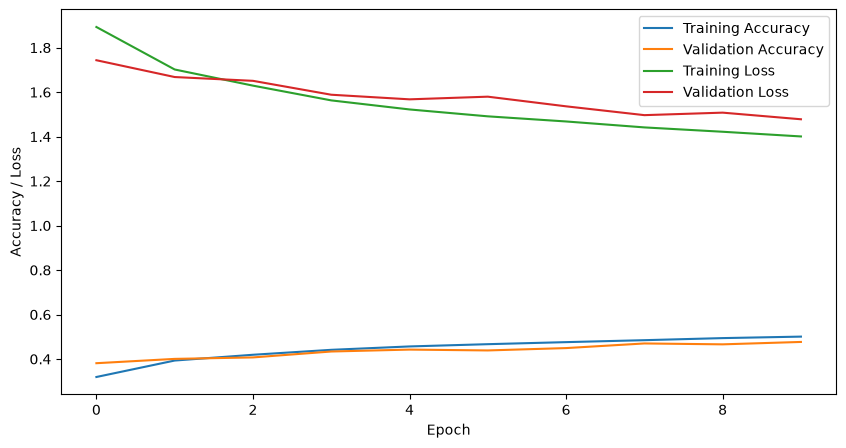

In [56]:
plt.figure(figsize=(10, 5))

plt.plot(h.history['accuracy'], label='Training Accuracy')
plt.plot(h.history['val_accuracy'], label='Validation Accuracy')
plt.plot(h.history['loss'], label='Training Loss')
plt.plot(h.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Accuracy / Loss')

plt.legend()
plt.show()